# Real-time planning with a JEPA world model on Ray

**V-JEPA 2-AC** (Meta, MIT license) can control a robot arm toward any goal you can photograph, with no task-specific training. The catch is speed. It picks each action by *searching*: it imagines hundreds of possible futures with its world model and keeps the one that lands closest to the goal. Meta reports 16 s per action on an RTX 4090. The arm stops, thinks, moves and stops again.

This notebook implements the design from *Real-Time JEPA World Models* on an **8× A100 node on Anyscale** and measures every step, end to end:

| | Seconds per action | vs. reference |
|---|---|---|
| Meta's reference planner, 1× A100 (fp32) | **81.8 s** | 1× |
| Same search, optimized model, 1× A100 | 21.4 s | 4× |
| **Ray Serve: search fanned out over 8× A100** | **2.86 s** | **29×** |
| + 3 search rounds per step instead of 10 (same accuracy on our task) | **0.86 s** | **96×** |
| + non-blocking control: plan the next step while the arm moves | robot never waits | |

Search settings throughout are the blog's: 800 candidate action sequences per round, the best 80 kept, horizon 2.

**Why Ray.** The search is embarrassingly parallel *within* a round and strictly sequential *across* rounds. That makes this a latency problem, not a throughput problem: every round has to fan out to every GPU and come back within milliseconds, ten times per action. Two composed **Ray Serve** deployments do exactly that:

- warm GPU replicas that keep the model resident between calls;
- a planner that fans each round out through a `DeploymentHandle`;
- scaling by changing a single replica count.

Ray adds about **10 ms per round** of overhead. On Anyscale the same code runs on whatever GPUs you attach.

## 0. Setup

All the code lives in a small package, `jepa_rt/`, which every worker receives through Ray's `runtime_env`:

| File | What it does |
|---|---|
| `jepa_rt/model.py` | Loads V-JEPA 2-AC; `encode(frame)`; `score(candidates)` → energy. No Ray in it. |
| `jepa_rt/cem.py` | The Cross-Entropy Method: `sample`, `refit`, `plan`. Same rules as Meta's reference. |
| `jepa_rt/serve_app.py` | The two Ray Serve deployments: `WorldModel` (GPU tier) and `Planner` (driver + HTTP endpoint). |

The driver (this notebook) never loads the model. Only GPU replicas do. On a cluster built from this repo's `Dockerfile`, everything is already installed, including a pinned copy of Meta's V-JEPA 2 code. On a stock Ray image, `runtime_env={"pip": ["timm"]}` installs the one missing package into a per-job virtual environment instead, so the cluster image is never modified. The 11.7 GB checkpoint lives on shared cluster storage (`TORCH_HOME`): `ensure_assets()` downloads it once, and every GPU reads that copy.

In [1]:
import os, sys, io, time, json, logging, warnings
warnings.filterwarnings("ignore")
import numpy as np
import requests
import matplotlib.pyplot as plt
import ray
from ray import serve
from IPython.display import Image, display

REPO = os.path.abspath(".")                      # run from v3_realtime_inference_for_jepa/
sys.path.insert(0, REPO)
from jepa_rt import EXAMPLE_TRAJ, RUNTIME_ENV, ensure_assets
from jepa_rt.serve_app import build_app

ensure_assets()                              # one-time downloads to shared storage (~12 GB); instant afterwards

logging.getLogger("ray.serve").setLevel(logging.ERROR)
ray.init(address="auto", runtime_env=RUNTIME_ENV, logging_level="ERROR", log_to_driver=False)
print("GPUs in the cluster:", int(ray.cluster_resources().get("GPU", 0)))

GPUs in the cluster: 8


## 1. Where the time goes: one action = 8,000 world-model evaluations

Planning one action with the Cross-Entropy Method (CEM) works like this:

1. Encode the camera frame and the goal image into latents (once).
2. **For each of 10 rounds:**
   - sample 800 candidate action sequences from a Gaussian;
   - roll each one forward through the predictor;
   - score how close the imagined final latent lands to the goal latent (L1 "energy");
   - refit the Gaussian to the best 80.
3. Execute the first action of the final mean, then start over from the next frame.

The expensive part is the predictor rollout, `score` in `jepa_rt/model.py`. It is the unit of work everything else is built around:

```python
energy = core.score(z, pose, z_goal, actions)   # actions [S, H, 7]  ->  energy [S]   (lower = closer to goal)
```

**Baseline.** Meta's reference planner (`cem()` in `notebooks/utils/mpc_utils.py`) runs unmodified, in fp32, on one A100-40GB. It takes **81.8 s per action** (three runs: 82.1 / 81.8 / 81.8 s).

**Single-GPU engineering, verified against the reference.** The same `score`, made faster:

| Change | Why it's safe |
|---|---|
| **KV cache across rollout steps** | The predictor is frame-causal, so earlier frames' keys and values never change. Each step computes only the new frame. |
| **bf16 + FlashAttention** | Once the cache removes the block-causal mask, each new frame attends to everything before it, so no mask is needed. |
| **`torch.compile`** on each transformer block | Same computation; it only fuses kernels. |
| **Pose update on the GPU** instead of per-sample scipy | CEM never samples rotations, so the orientation is unchanged. |

On 128 random candidates the fast path matches the reference energies with Pearson r = 0.9999 (max |Δ| = 4e-4 on a 0.45–0.49 range). One round of 800 candidates drops from **8.2 s to 2.1 s**. The script is `scripts/check_fast_path.py`, and the results are in `results/01_*.json` and `results/02_*.json`.

That's 4× on one GPU, still 21 s per action. The rest has to come from more GPUs.

## 2. The service: two composed Ray Serve deployments

The 800 candidates in a round are independent, so we split them into W shards and score each shard on its own GPU. The 10 rounds stay sequential.

![two deployments](images/architecture.png)

**`WorldModel`** is the GPU tier: one replica per GPU, weights resident, one shard at a time (from `jepa_rt/serve_app.py`, with logging trimmed):

```python
@serve.deployment(
    ray_actor_options={"num_gpus": 1},
    max_ongoing_requests=1,          # one shard at a time, so a W-way fan-out lands one shard per GPU
    request_router_config=RequestRouterConfig(
        request_router_class="ray.serve.experimental.round_robin_router:RoundRobinRouter"),
)
class WorldModel:
    def __init__(self, warmup_shard_sizes=(100,), horizon=2):
        os.environ.pop("TORCHDYNAMO_DISABLE", None)   # see section 4
        self.core = WorldModelCore()                 # load encoder + predictor once; they stay resident
        ...                                          # compile + warm up before taking traffic

    def encode(self, frame): ...

    async def score(self, ctx, actions):
        if isinstance(ctx, ray.ObjectRef):           # latents: read from the object store once per plan,
            ctx = await ctx                          # then kept on this GPU for every round
        ...
        return self.core.score(z, pose, z_goal, actions).cpu().numpy(), timing
```

**`Planner`** is the driver. It runs the CEM rounds and fans each one out across the replicas:

```python
@serve.deployment(max_ongoing_requests=32)
@serve.ingress(app)
class Planner:
    async def plan(self, frame, pose, goal_frame, warm=None, rounds=None, ...):
        z, z_goal = await asyncio.gather(self.wm.encode.remote(frame), self._goal_latent(goal_frame))
        ctx = ray.put({"key": uuid4().hex, "z": z, "pose": pose, "z_goal": z_goal})   # 2.8 MB, put once
        dist = CEMDistribution(horizon=2)
        for _ in range(rounds):                                     # sequential: the floor
            cands = dist.sample(800)
            results = await asyncio.gather(*[self.wm.score.remote(ctx, shard)          # fan out ...
                                             for shard in np.array_split(cands, self.n_shards)])
            dist.refit(cands, np.concatenate([e for e, _ in results]))               # ... gather, refit
        return {"action": dist.action(), "warm": {...}, "timing_ms": {...}}

def build_app(n_gpus=8, ...):           # the only knob for scale
    return Planner.bind(WorldModel.options(num_replicas=n_gpus).bind(...), n_shards=n_gpus, ...)
```

Three design choices carry it:

- **Latents move once per plan, not once per round.** The 2.8 MB of observation and goal latents go into Ray's object store with one `ray.put`. Every replica reads them from shared memory and caches them on its GPU, so each round ships only ~5 KB of candidate actions out and 400 bytes of energies back.
- **A fixed replica count.** `num_replicas` is pinned rather than autoscaled, so the per-round latency is predictable.
- **A stateless planner.** A reply carries its CEM state (`warm`), and the robot sends it back with its next request. Any `Planner` replica can serve any robot, so the driver tier scales out freely.

In [2]:
# Deploy: 8 WorldModel replicas (one per A100) + the Planner. Each replica loads the model and compiles before it
# takes traffic (~50 s), so the first request is not a cold start.
t = time.time()
serve.run(build_app(n_gpus=8), name="jepa_planner", route_prefix="/jepa")
print(f"deployed in {time.time() - t:.0f} s")
URL = "http://127.0.0.1:8000/jepa"
print(requests.get(URL + "/health", timeout=30).json())

deployed in 48 s
{'ok': True, 'gpus': 8, 'samples': 800, 'rounds': 10}


## 3. A robot calls it

The robot side is a plain HTTP client. It sends a camera frame, its 7-D end-effector pose and the goal image, and gets back the next action. We use the context and goal frames from Meta's example Franka trajectory.

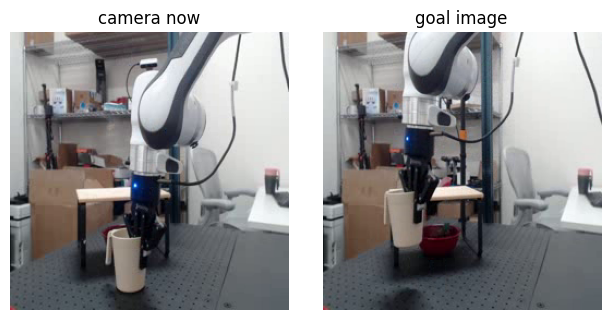

full search (800 x 10 rounds on 8 GPUs):   2913 ms round trip | action dxyz = [5.   5.   4.98] cm, gripper +0.34


full search (800 x 10 rounds on 8 GPUs):   2915 ms round trip | action dxyz = [5.   5.   4.97] cm, gripper +0.33


full search (800 x 10 rounds on 8 GPUs):   2913 ms round trip | action dxyz = [5.   4.99 4.98] cm, gripper +0.40


In [3]:
traj = np.load(EXAMPLE_TRAJ)                      # Meta's example Franka trajectory, shipped with V-JEPA 2
frame, goal_frame, pose = traj["observations"][0][0], traj["observations"][0][-1], traj["states"][0][0]

def robot_request(frame, pose, goal_frame, warm=None, rounds=None):
    buf = io.BytesIO()
    extra = {} if warm is None else {"warm_mean": warm[0], "warm_std": warm[1]}
    if rounds: extra["rounds"] = rounds
    np.savez(buf, frame=frame, pose=pose.astype(np.float32), goal_frame=goal_frame, **extra)
    t = time.perf_counter()
    r = requests.post(URL + "/plan", data=buf.getvalue(), timeout=120)
    rtt = (time.perf_counter() - t) * 1e3
    out = np.load(io.BytesIO(r.content))
    return out, rtt

fig, ax = plt.subplots(1, 2, figsize=(6.4, 3.2))
for a, im, title in zip(ax, (frame, goal_frame), ("camera now", "goal image")):
    a.imshow(im); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

robot_request(frame, pose, goal_frame)                       # first call encodes + caches the goal image
for i in range(3):
    out, rtt = robot_request(frame, pose, goal_frame)
    print(f"full search (800 x 10 rounds on 8 GPUs): {rtt:6.0f} ms round trip | "
          f"action dxyz = {np.round(out['action'][:3] * 100, 2)} cm, gripper {out['action'][6]:+.2f}")

About **2.9 s** per action, down from 81.8 s. The Python handle shows where the time goes inside one plan:

In [4]:
h = serve.get_app_handle("jepa_planner")
r = await h.plan.remote(frame, pose, goal_frame, seed=0)   # handle calls are awaitables
tm = r["timing_ms"]
print(f"total {tm['total']:.0f} ms = encode {tm['encode']:.0f} ms + 10 rounds x ~{np.median(tm['rounds']):.0f} ms")
print(f"per round: GPU compute {np.median(tm['gpu']):.0f} ms (slowest of 8 shards), "
      f"Ray fan-out + gather + refit {np.median(np.array(tm['rounds']) - np.array(tm['gpu'])):.0f} ms")

total 2884 ms = encode 52 ms + 10 rounds x ~283 ms
per round: GPU compute 277 ms (slowest of 8 shards), Ray fan-out + gather + refit 6 ms


**Ray's share of each round is under 10 ms**, i.e. about 3%. That covers sampling the candidates, eight handle calls, the replicas reading the latents from the object store, and gathering and refitting. The rest is the GPUs doing model math.

## 4. Scaling: one number in the config

`build_app(n_gpus=W)` sets both the replica count and the fan-out width. Measured on this node (`scripts/bench_scaling.py`, five plans per point, results in `results/03_scaling.json`):

1 GPU : 21.42 s per plan (1.00x) | round 2138 ms, of which GPU 2132 ms | final elite energy 0.44854
2 GPUs: 10.82 s per plan (1.98x) | round 1078 ms, of which GPU 1072 ms | final elite energy 0.44854
4 GPUs:  5.53 s per plan (3.88x) | round 548 ms, of which GPU 542 ms | final elite energy 0.44854
8 GPUs:  2.86 s per plan (7.48x) | round 281 ms, of which GPU 274 ms | final elite energy 0.44854


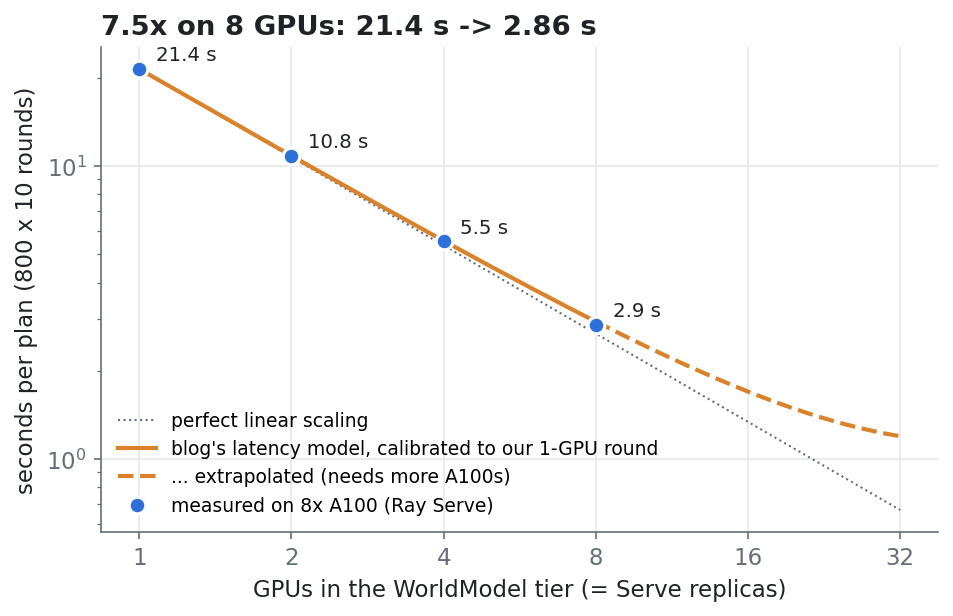

In [5]:
sc = json.load(open("results/03_scaling.json"))
for w in sorted(sc, key=int):
    v = sc[w]
    print(f"{w} GPU{'s' if w != '1' else ' '}: {v['plan_ms_median'] / 1e3:5.2f} s per plan "
          f"({sc['1']['plan_ms_median'] / v['plan_ms_median']:.2f}x) | round {v['round_ms_median']:.0f} ms, "
          f"of which GPU {v['gpu_ms_median']:.0f} ms | final elite energy {np.mean(v['final_elite_energy']):.5f}")
display(Image("images/scaling.png", width=640))

- **7.5× on 8 GPUs, and the plans are identical at every GPU count.** With the same seed, 1, 2, 4 and 8 GPUs return the same action to four decimals. Sharding changes how fast the search runs, not what it finds.
- **The blog's latency model holds.** Calibrated on our measured 1-GPU round (2.14 s), its formula `10 × (round / effective(W) + 1 ms × (W−1))` predicts 2.89 s at 8 GPUs. We measured **2.86 s**.

**Two things we had to fix** to get there, both one-liners and both worth knowing:

1. **Routing.** With `max_ongoing_requests=1`, Serve's default power-of-two-choices router occasionally sent two shards to the same replica while another sat idle. That round took twice as long, and the median plan was 6.1 s. Serve's round-robin router assigns the 8 shards of a round to 8 consecutive replicas: zero collisions in 50 rounds.
2. **`torch.compile` inside Serve.** Our replica processes start with `TORCHDYNAMO_DISABLE=1` in their environment, so `torch.compile` silently did nothing (372 ms per shard instead of 272). Removing the variable in `__init__`, before torch is imported, restores it.

## 5. Shrinking the sequential floor: fewer rounds per step

More GPUs shrink each round, but the 10 rounds still run one after another. At 8 GPUs that's 10 × 282 ms. The blog's next suggestion is to attack the floor.

We ran closed-loop episodes in which the world model stands in for the robot: every executed action is rolled forward through the predictor to produce the next observation. The goal is 21.6 cm away. It is made reachable by rolling a known action sequence forward from the start, so we can measure the physical error in centimetres (`scripts/bench_closed_loop.py`, 3 seeds × 12 steps per strategy):

10 rounds per step (paper)  : 21.6 cm -> 4.1 cm after 12 steps (closest 2.7) |  2831 ms per step
3 rounds per step           : 21.6 cm -> 4.2 cm after 12 steps (closest 3.2) |   854 ms per step
3 rounds, warm-started      : 21.6 cm -> 4.0 cm after 12 steps (closest 3.0) |   855 ms per step
2 rounds, warm-started      : 21.6 cm -> 4.0 cm after 12 steps (closest 3.0) |   571 ms per step


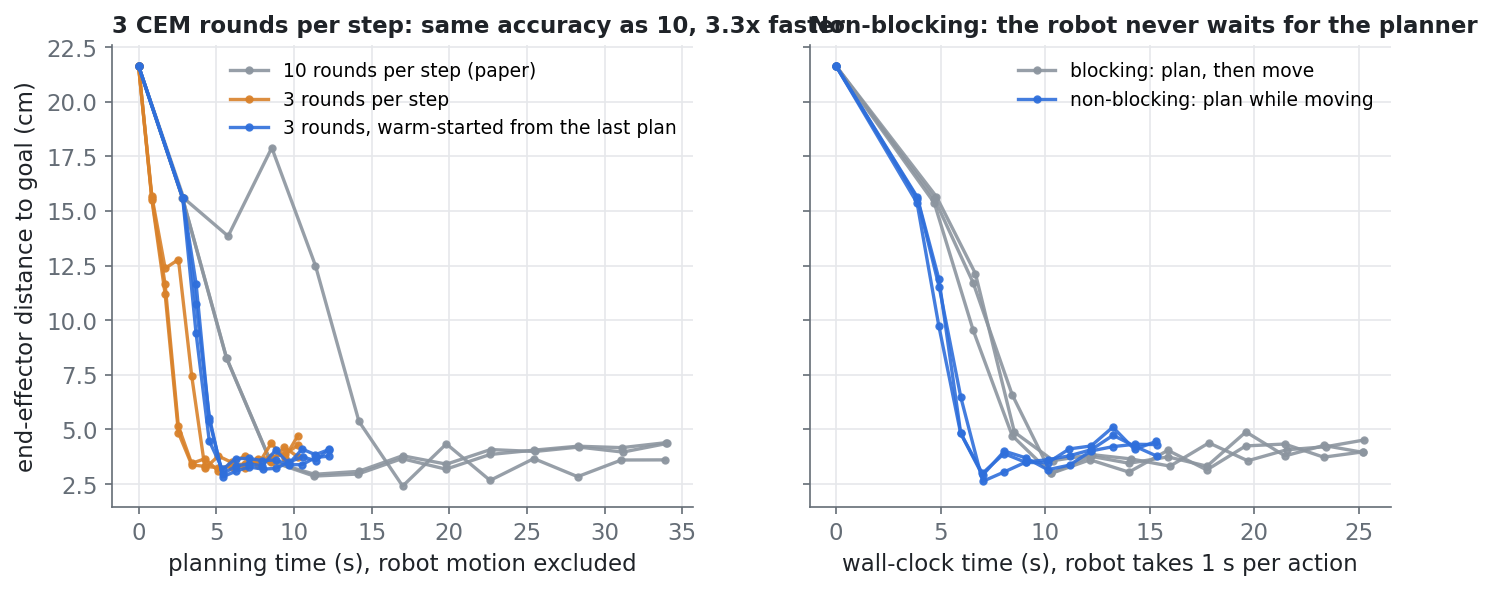

In [6]:
cl = json.load(open("results/04_closed_loop.json"))
for s, name in (("cold10", "10 rounds per step (paper)"), ("cold3", "3 rounds per step"),
                ("warm3", "3 rounds, warm-started"), ("warm2", "2 rounds, warm-started")):
    runs = cl[s].values()
    final = np.mean([v["dist_cm"][-1] for v in runs]); best = np.mean([min(v["dist_cm"]) for v in runs])
    ms = np.median([np.median(v["plan_ms"][1:]) for v in runs])
    print(f"{name:28s}: 21.6 cm -> {final:.1f} cm after 12 steps (closest {best:.1f}) | {ms:5.0f} ms per step")
display(Image("images/closed_loop.png", width=900))

**On this task, 3 rounds per step reach the same accuracy as 10 in 3.3× less time: 0.86 s per action, 96× faster than the reference.** Every strategy settles at about 3.5–4 cm, which is the precision floor of planning in this model's latent space, not of the search.

A note of caution: warm-starting each search from the previous plan (the blog's suggestion B) worked, but on this task it was no better than a fresh 3-round search. The win here comes from running fewer rounds, and how many a task needs is a dial to tune per task.

## 6. Non-blocking control: hide what's left

Even at 0.86 s, a blocking controller still stops between moves: plan, move, plan, move. The blog's suggestion A is to plan step t+1 *while the arm executes step t*, starting from the world model's prediction of where step t will land.

We timed both in wall-clock time (`scripts/bench_nonblocking.py`). The simulated arm takes 1 s per action, and its execution is noisy (4 mm per axis), so the prediction it plans from is slightly wrong. Results, 3 seeds × 12 steps:

| | time per step | 12-step episode | final distance |
|---|---|---|---|
| blocking | 1.86 s (= 0.86 plan + 1.0 move) | 25.3 s | 4.2 cm |
| **non-blocking** | **1.04 s** (= the move itself + 40 ms) | **15.3 s** | **4.2 cm** |

The robot moves continuously, and the planner's latency disappears behind the motion. On the Ray side this needs nothing new: the planning call is an awaitable, so the robot just doesn't wait on it.

Here is a live non-blocking episode against the service we deployed above:

In [7]:
import asyncio
wm = serve.get_deployment_handle("WorldModel", app_name="jepa_planner")
z0 = await wm.encode.remote(frame)
p0 = pose.astype(np.float32)
a_star = np.zeros((6, 7), np.float32); a_star[:, :3] = [0.03, 0.02, 0.0]
z_goal, p_goal = await wm.simulate.remote(z0, p0, a_star)          # a reachable goal, 21.6 cm away
dist = lambda p: np.linalg.norm(p_goal[:3] - p[:3]) * 100

async def move(z, p, a, rng, exec_s=1.0):                          # the "robot": 1 s per action, 4 mm error
    noisy = a.copy(); noisy[:3] += rng.normal(0, 0.004, 3)
    t = time.perf_counter(); nxt = await wm.simulate.remote(z, p, noisy[None])
    await asyncio.sleep(max(0, exec_s - (time.perf_counter() - t)))
    return nxt

async def nonblocking_episode(steps=8, seed=0):
    rng = np.random.default_rng(seed)
    z, p, t0 = z0, p0, time.perf_counter()
    out = await h.plan.remote(None, p, None, z=z, z_goal=z_goal, seed=seed)       # first plan: full search
    print(f"t={time.perf_counter() - t0:4.1f} s  distance {dist(p):4.1f} cm  (first plan: full 10-round search)")
    for t in range(steps):
        z_pred, p_pred = await wm.simulate.remote(z, p, out["action"][None])    # where this action should land
        moving = asyncio.ensure_future(move(z, p, out["action"], rng))          # the arm starts moving ...
        planning = h.plan.remote(None, p_pred, None, z=z_pred, z_goal=z_goal,   # ... while we plan the next step
                                 warm=out["warm"], rounds=3, seed=seed + t + 1)
        (z, p), out = await asyncio.gather(moving, planning)
        print(f"t={time.perf_counter() - t0:4.1f} s  distance {dist(p):4.1f} cm  "
              f"(planned in {out['timing_ms']['total']:.0f} ms while the arm moved for 1 s)")

await nonblocking_episode()

t= 2.9 s  distance 21.6 cm  (first plan: full 10-round search)


t= 3.9 s  distance 15.7 cm  (planned in 872 ms while the arm moved for 1 s)


t= 5.0 s  distance 11.9 cm  (planned in 873 ms while the arm moved for 1 s)


t= 6.0 s  distance  4.8 cm  (planned in 871 ms while the arm moved for 1 s)


t= 7.1 s  distance  2.9 cm  (planned in 871 ms while the arm moved for 1 s)


t= 8.1 s  distance  4.0 cm  (planned in 874 ms while the arm moved for 1 s)


t= 9.1 s  distance  3.7 cm  (planned in 873 ms while the arm moved for 1 s)


t=10.2 s  distance  3.2 cm  (planned in 871 ms while the arm moved for 1 s)


t=11.2 s  distance  3.5 cm  (planned in 871 ms while the arm moved for 1 s)


## 7. What this means at the scale in the blog

All the numbers above are measured on one node of 8× A100-40GB. The blog sizes the problem for **32× H100** (four 8-GPU nodes). We didn't run that, so the following is a **projection**, using the blog's own latency model calibrated to our measurements. Two inputs:

- **Our measured 1-GPU round on an A100:** 2.14 s for 800 candidates.
- **The blog's assumption of 2× for an H100** over a 4090. We assume 2× over our A100 too, which is conservative: the H100 has ~3× the bf16 throughput.

The projection:

In [8]:
def blog_model(W, round_1gpu_s, rounds=10, encode_s=0.05):
    eff = W / (1 + 0.008 * (W - 1))
    return rounds * (round_1gpu_s / eff + 0.001 * (W - 1)) + encode_s

r_a100 = sc["1"]["round_ms_median"] / 1e3
print(f"model check, 8x A100 : {blog_model(8, r_a100):.2f} s predicted vs {sc['8']['plan_ms_median'] / 1e3:.2f} s measured")
for gpu, r in (("A100", r_a100), ("H100 (assumed 2x A100)", r_a100 / 2)):
    print(f"32x {gpu:23s}: 10 rounds {blog_model(32, r):.2f} s | 3 rounds {blog_model(32, r, rounds=3):.2f} s per action (projected)")

model check, 8x A100 : 2.94 s predicted vs 2.86 s measured
32x A100                   : 10 rounds 1.19 s | 3 rounds 0.39 s per action (projected)
32x H100 (assumed 2x A100) : 10 rounds 0.78 s | 3 rounds 0.27 s per action (projected)


At 32× H100 the projection lands at about **0.8 s for the full 10-round search** and about **0.3 s with 3 rounds**. That's in line with the blog's 0.6 s, and now it is anchored on measurements rather than on a single published number. The scaling curve flattens beyond ~16 GPUs because each GPU's shard of 800 candidates gets small. A real deployment would grow the search (more candidates) or serve more robots per GPU tier rather than keep slicing one search thinner.

## 8. Takeaways

- **The search is the cost, and it parallelizes.** 800 candidates per round are independent. Ray Serve fans them out to warm GPU replicas and gathers them in under 10 ms per round. We measured 7.5× on 8 GPUs, with the same plans as on one.
- **Ray turns the blog's design into one ~170-line file.** It takes two `@serve.deployment` classes, one `DeploymentHandle`, `asyncio.gather` for the fan-out, `ray.put` to share the latents, and `runtime_env` to ship code and dependencies without touching the image. Scaling is `num_replicas`.
- **Systems and algorithm together give 96×.** A faster model on one GPU (4×), the Ray Serve fan-out (7.5×) and fewer rounds per step (3.3×) multiply: 81.8 s becomes 0.86 s per action on 8× A100. Non-blocking control then hides even that behind the arm's motion.
- **On Anyscale, the GPU count is a deployment parameter.** The same `build_app(n_gpus=...)` that ran here on 8 A100s runs on 32 H100s.

In [9]:
serve.delete("jepa_planner")      # release the 8 GPUs
print("released")

released
